# T39 — A global apparent polar wander path draped on reconstructed continents


**Cluster F: Paleomagnetism.**
**Plot the global apparent polar wander path (APWP) of Vaes et al. (2023), referenced to the South African plate, on continents that are reconstructed to each pole's age in the same South Africa-fixed frame — so the position of the spin axis and the continents are shown together at every time step.**

## What this notebook produces

An APWP is usually plotted as one static map: all poles in present-day coordinates, as a track from old to young. A pole is a statement about where the spin axis was *in the coordinates of one plate* (here South Africa). To see what that means geographically, the continents have to be placed in the same frame. This notebook therefore reconstructs all continents to age *t* **with South Africa held fixed** (`anchor_plate_id = 701`) and over-plots the APWP poles up to that age, coloured by age. The star marks the pole closest in age to *t*, i.e. the position of the north rotation axis at that time in South African coordinates. The result, stepped through time with a Panel slider, shows the continents moving around the pole instead of the pole moving across a fixed map.

We use the Vaes et al. (2023) global APWP in the South African frame, bundled as `data/paleomag/vaes2023_global_apwp.csv` (33 poles, 1.4–320.2 Ma, rounded to one decimal), and the Zahirovic 2022 plate model. Zahirovic 2022 provides the relative positions of the continents at each age; the absolute paleolatitudes come from the poles.

**Scope.** The pole table stops at 320 Ma, so the maps stop there too. Poles are tabulated at irregular ages (about every 5–20 Myr), and the star shows the nearest tabulated pole rather than an interpolated one.

**Audience**: undergrad → postgrad.
**Difficulty**: ★★☆.

## Learning objectives

- Read an apparent polar wander path from a CSV table of (age, pole_lat, pole_lon, A95).
- Understand that a pole is defined in the coordinates of a specific plate, and reconstruct the continents in that plate's frame by choosing `anchor_plate_id`.
- Loop reconstruction time and APWP age together to produce one paleo-frame per pole.
- Wrap the result in a Panel slider that lets the user scrub through time.

## Prerequisites and runtime

- Plate model: Zahirovic 2022 (South Africa = plate 701).
- Bundled data: `data/paleomag/vaes2023_global_apwp.csv`.
- Python: `gplately`, `pygmt`, `pygplates`, `pandas`, `panel`.
- Runtime: about 1 minute for the static panels; the slider renders each frame as a PNG (about 3 s per frame).


In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np
import pandas as pd
import gplately
import pygmt
import pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
import panel as pn
from IPython.display import display, HTML
pn.extension()
# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0.post19+git.2cce7bb3  pygmt v0.19.0  pygplates 1.0.0


## Configuration — change the APWP CSV + plate model here

In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME    = "Zahirovic2022"
APWP_CSV      = "data/paleomag/vaes2023_global_apwp.csv"   # Vaes et al. (2023), South African frame
ANCHOR_PLATE_ID = 701                   # frame of the APWP (South Africa); change together with the APWP
MAX_AGE_MA    = 320                     # last tabulated pole of the APWP is 320.2 Ma
AGES_TO_RENDER = (0, 50, 150, 250, 320) # static-panel ages
# ============================================================================


## 1. Load the APWP table

A CSV with columns `age` (Ma), `pole_lat`, `pole_lon`, `A95` (degrees), in the South African reference frame. Lines starting with `#` are comments.


In [3]:
# Cell 2 — load APWP
apwp = pd.read_csv(APWP_CSV, comment="#")
assert {"age", "pole_lat", "pole_lon"} <= set(apwp.columns), apwp.columns
print(f"loaded {len(apwp)} APWP poles, {apwp['age'].min():.1f}-{apwp['age'].max():.1f} Ma")
apwp.head()


loaded 33 APWP poles, 1.4-320.2 Ma


,age,pole_lat,pole_lon,A95
0,1.4,89.4,143.0,0.7
1,4.6,87.8,166.6,1.2
2,21.5,82.7,192.5,1.1
3,28.2,80.8,203.5,1.0
4,37.6,79.6,206.3,1.3


## 2. Load the plate model + reconstruction in the South African frame

`anchor_plate_id=701` holds South Africa fixed, so the reconstructed continents are expressed in the same frame as the poles.


In [4]:
# Cell 3 — load model
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="./gplately_data")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID,
)


## 3. Render one paleogeographic reconstruction per snapshot

For each age, reconstruct the continents to that age in the South African frame and over-plot the APWP poles up to and including that age, coloured by their own age. The star is the pole closest in age to the map age.



=== 0 Ma ===


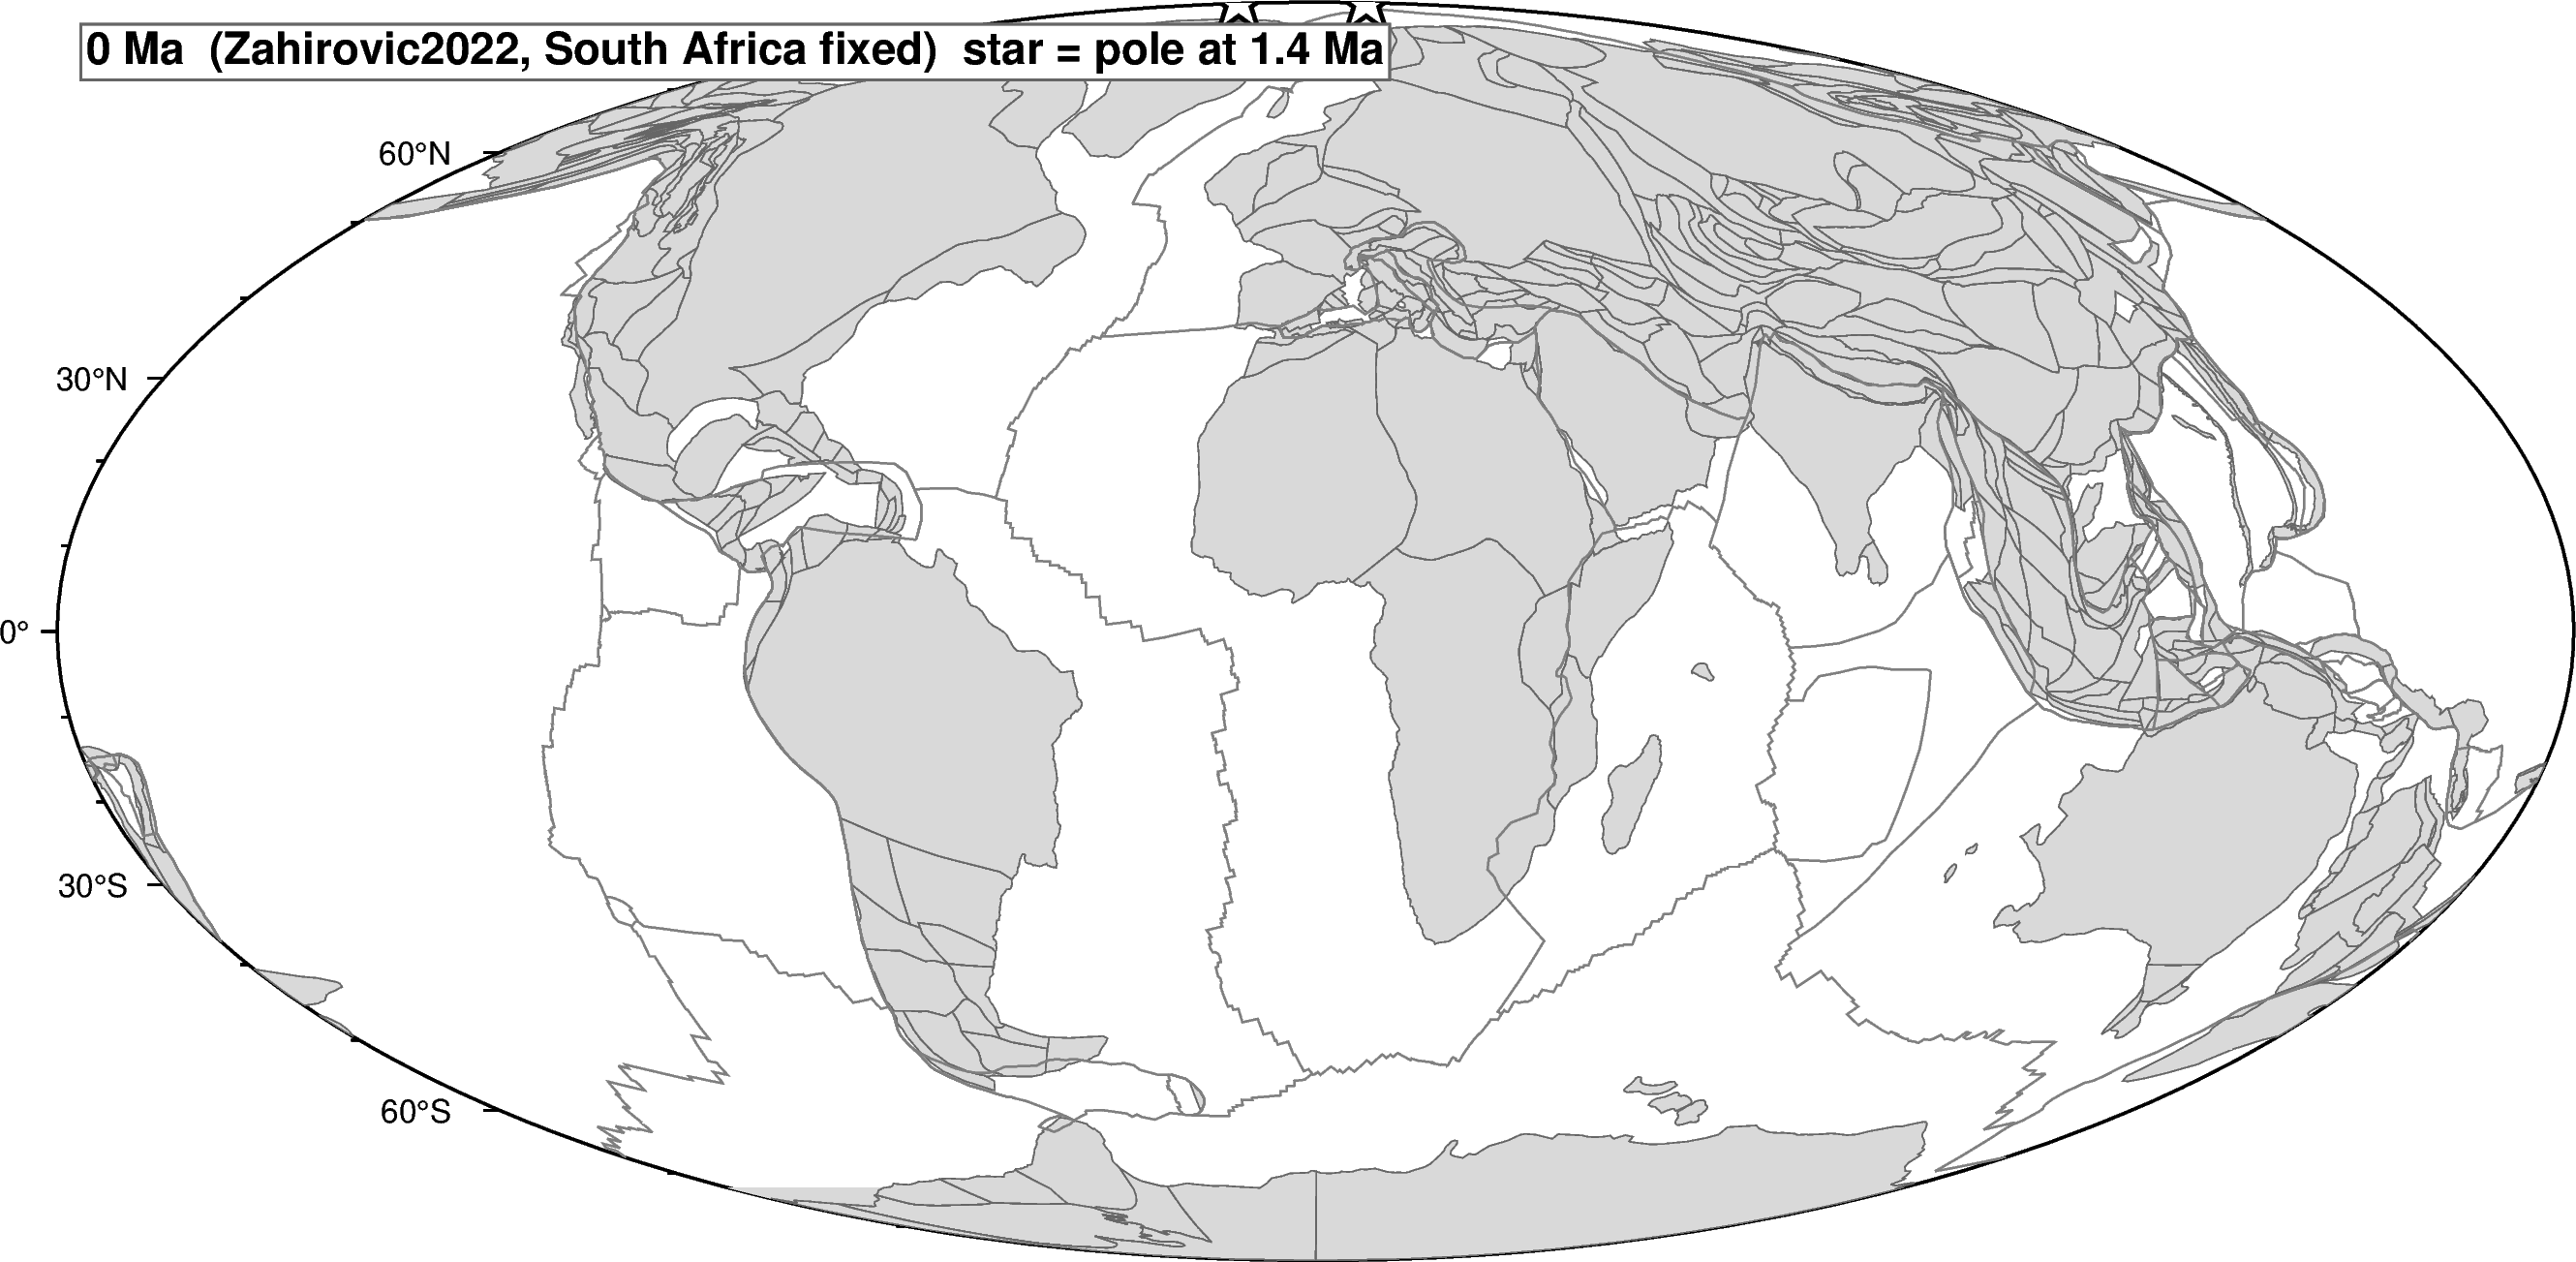


=== 50 Ma ===


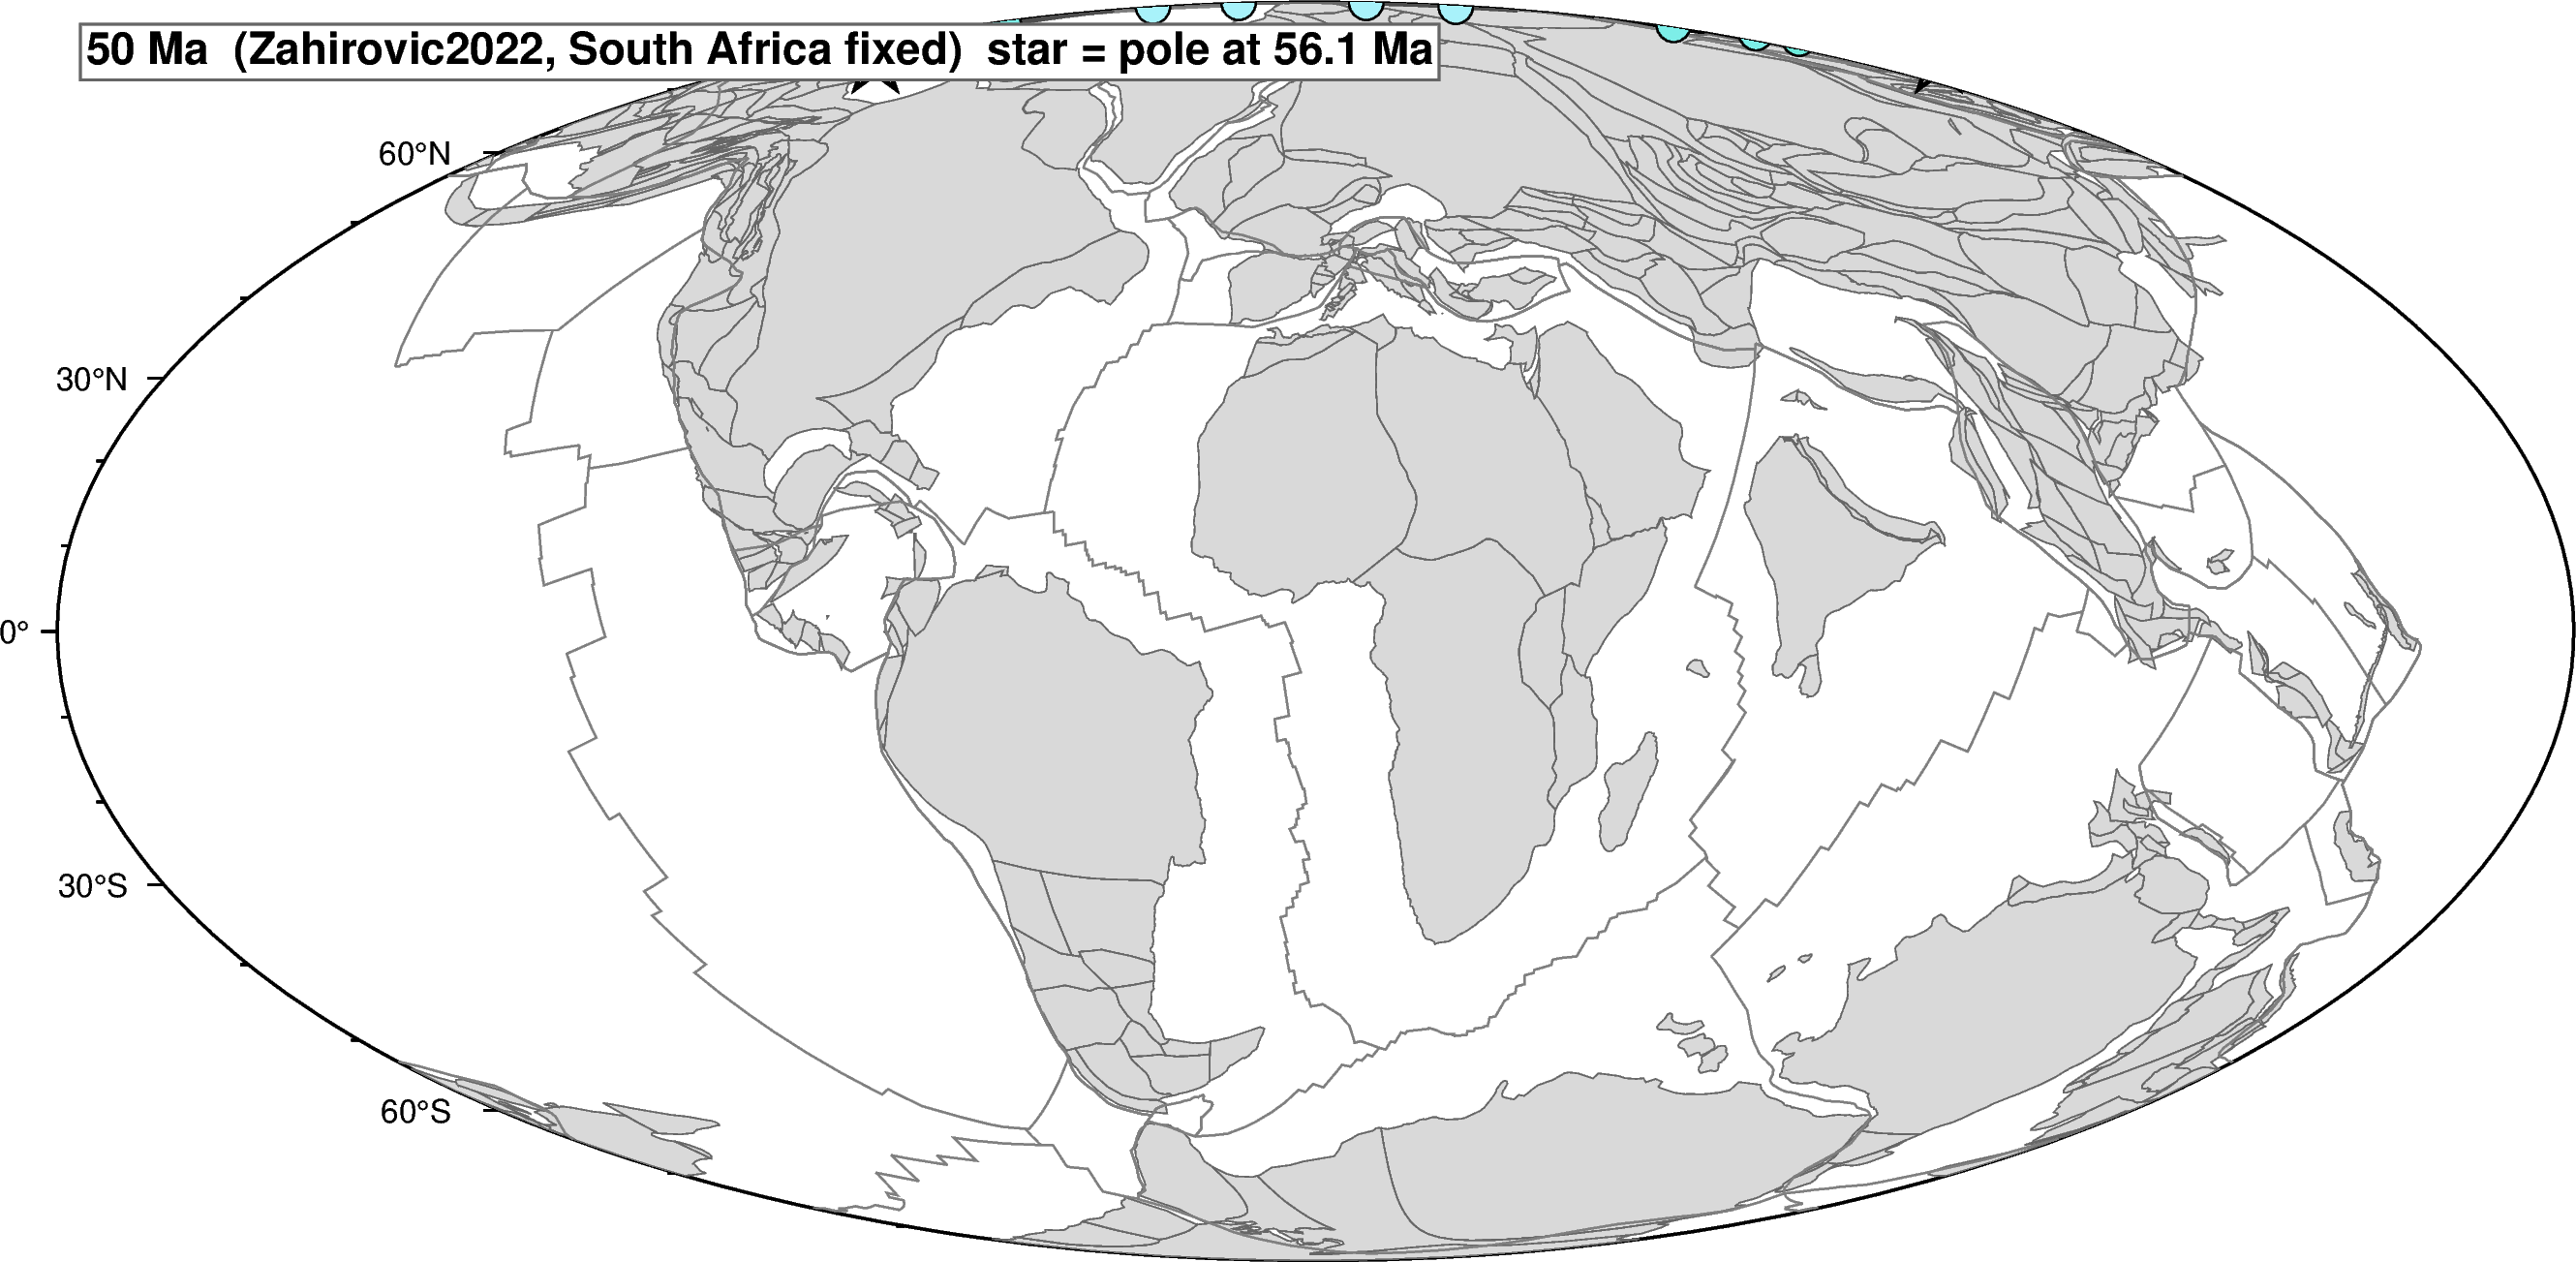


=== 150 Ma ===


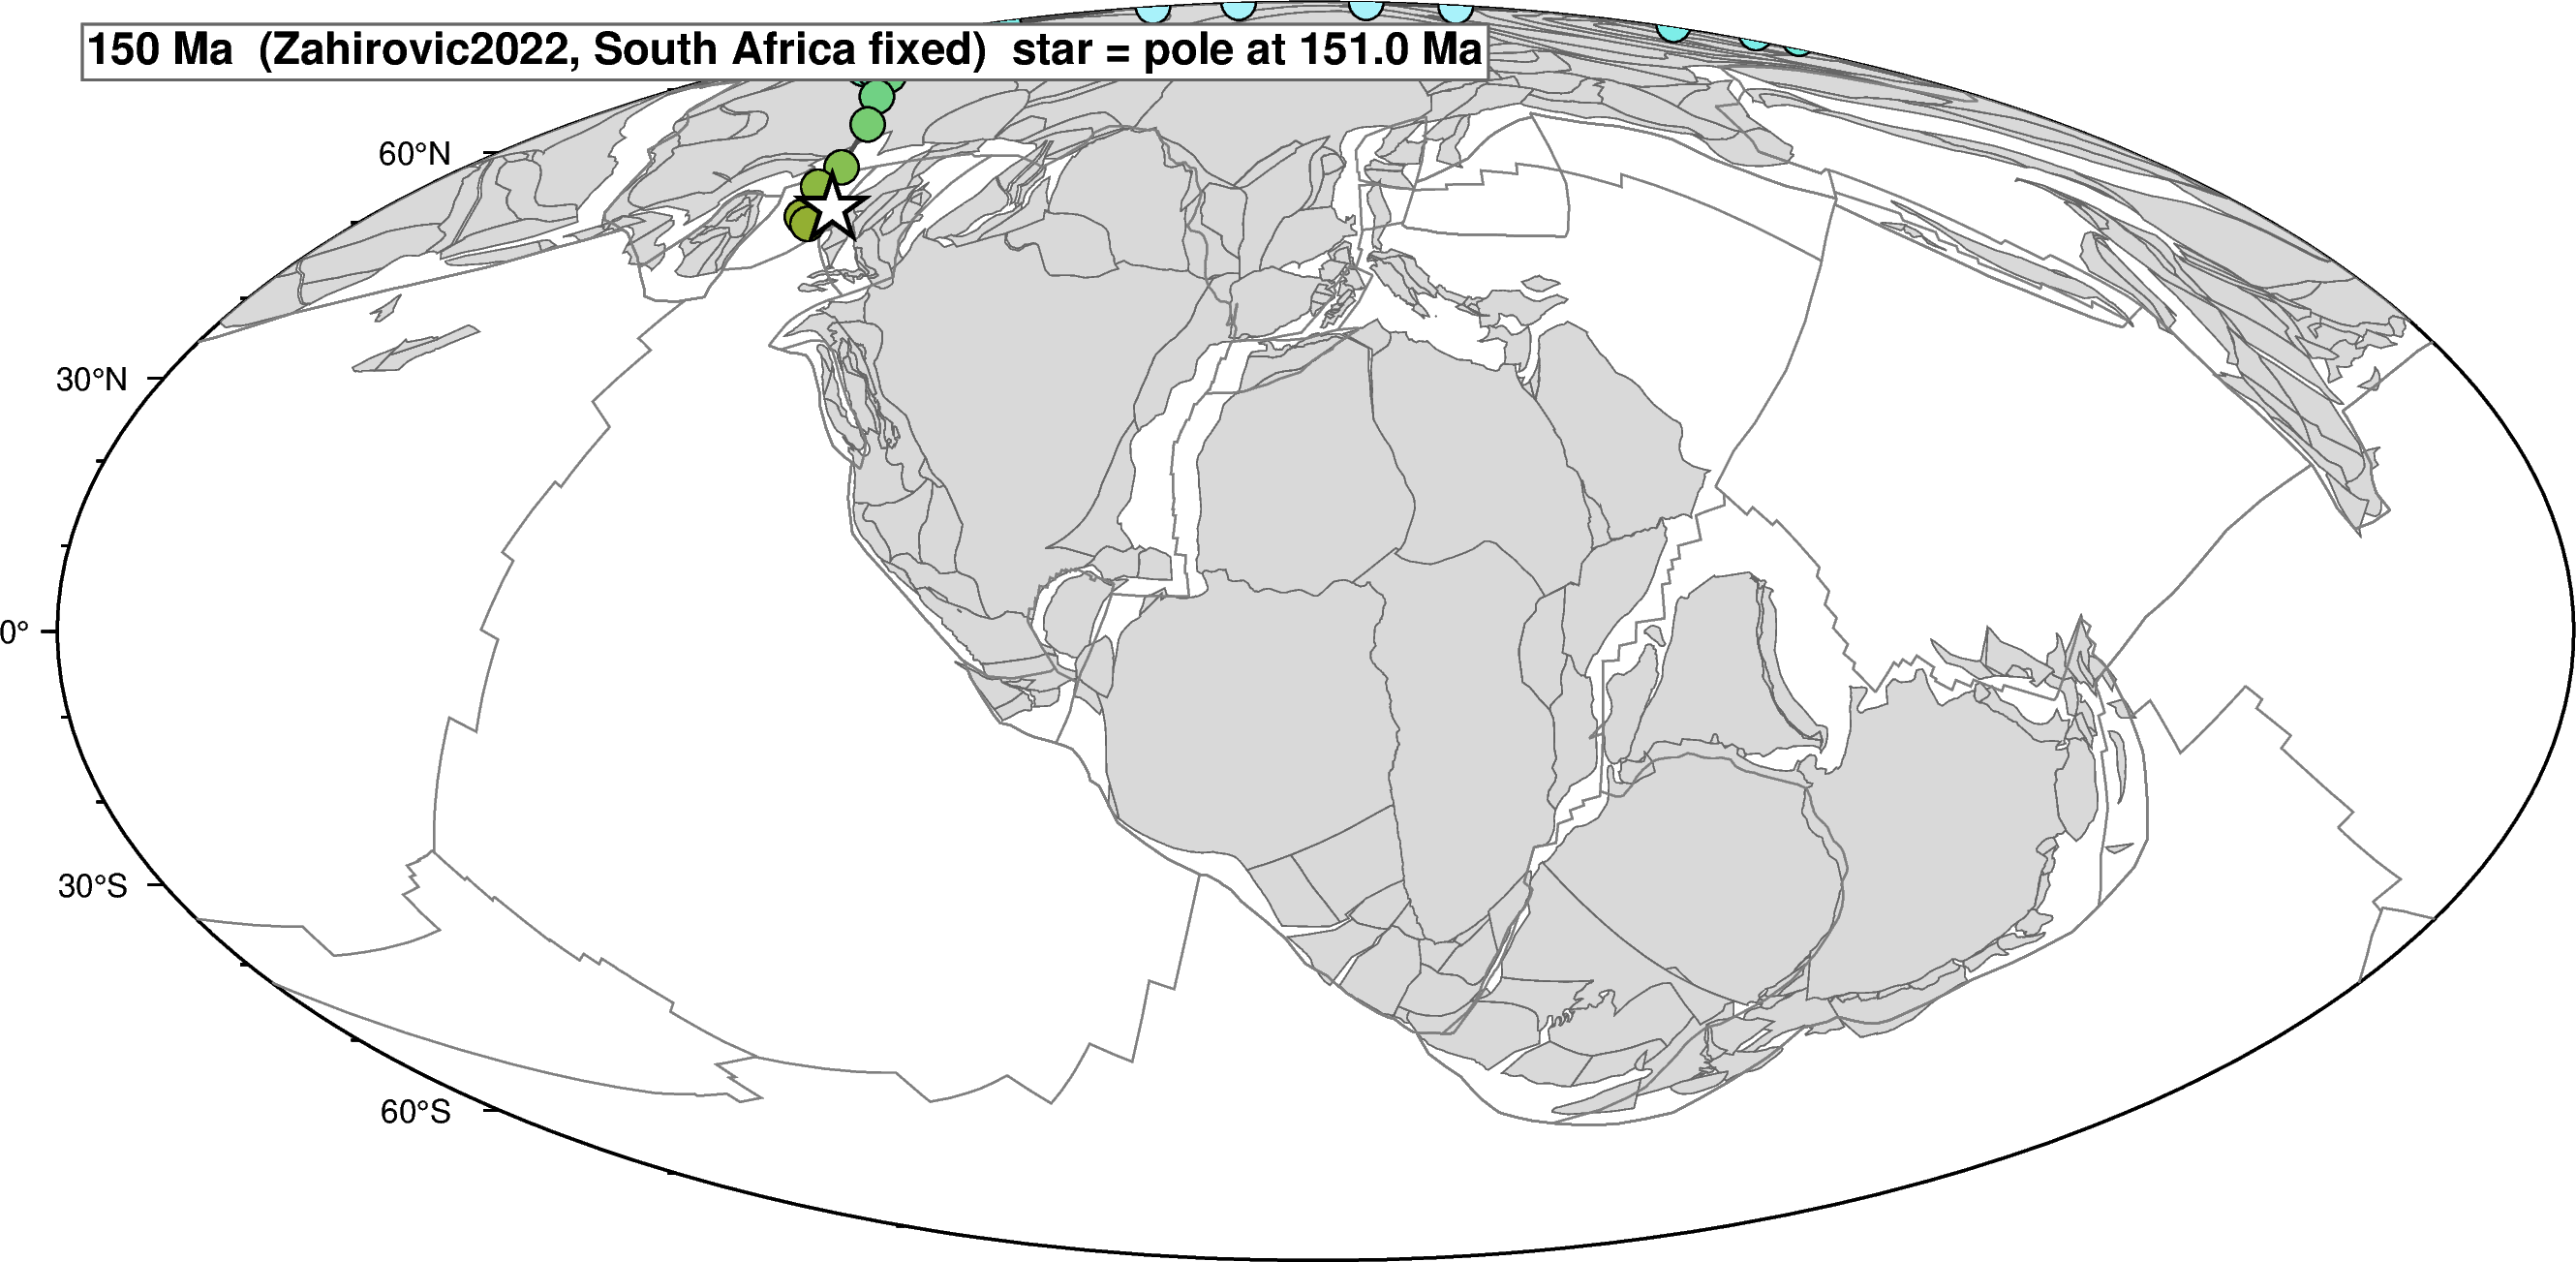


=== 250 Ma ===


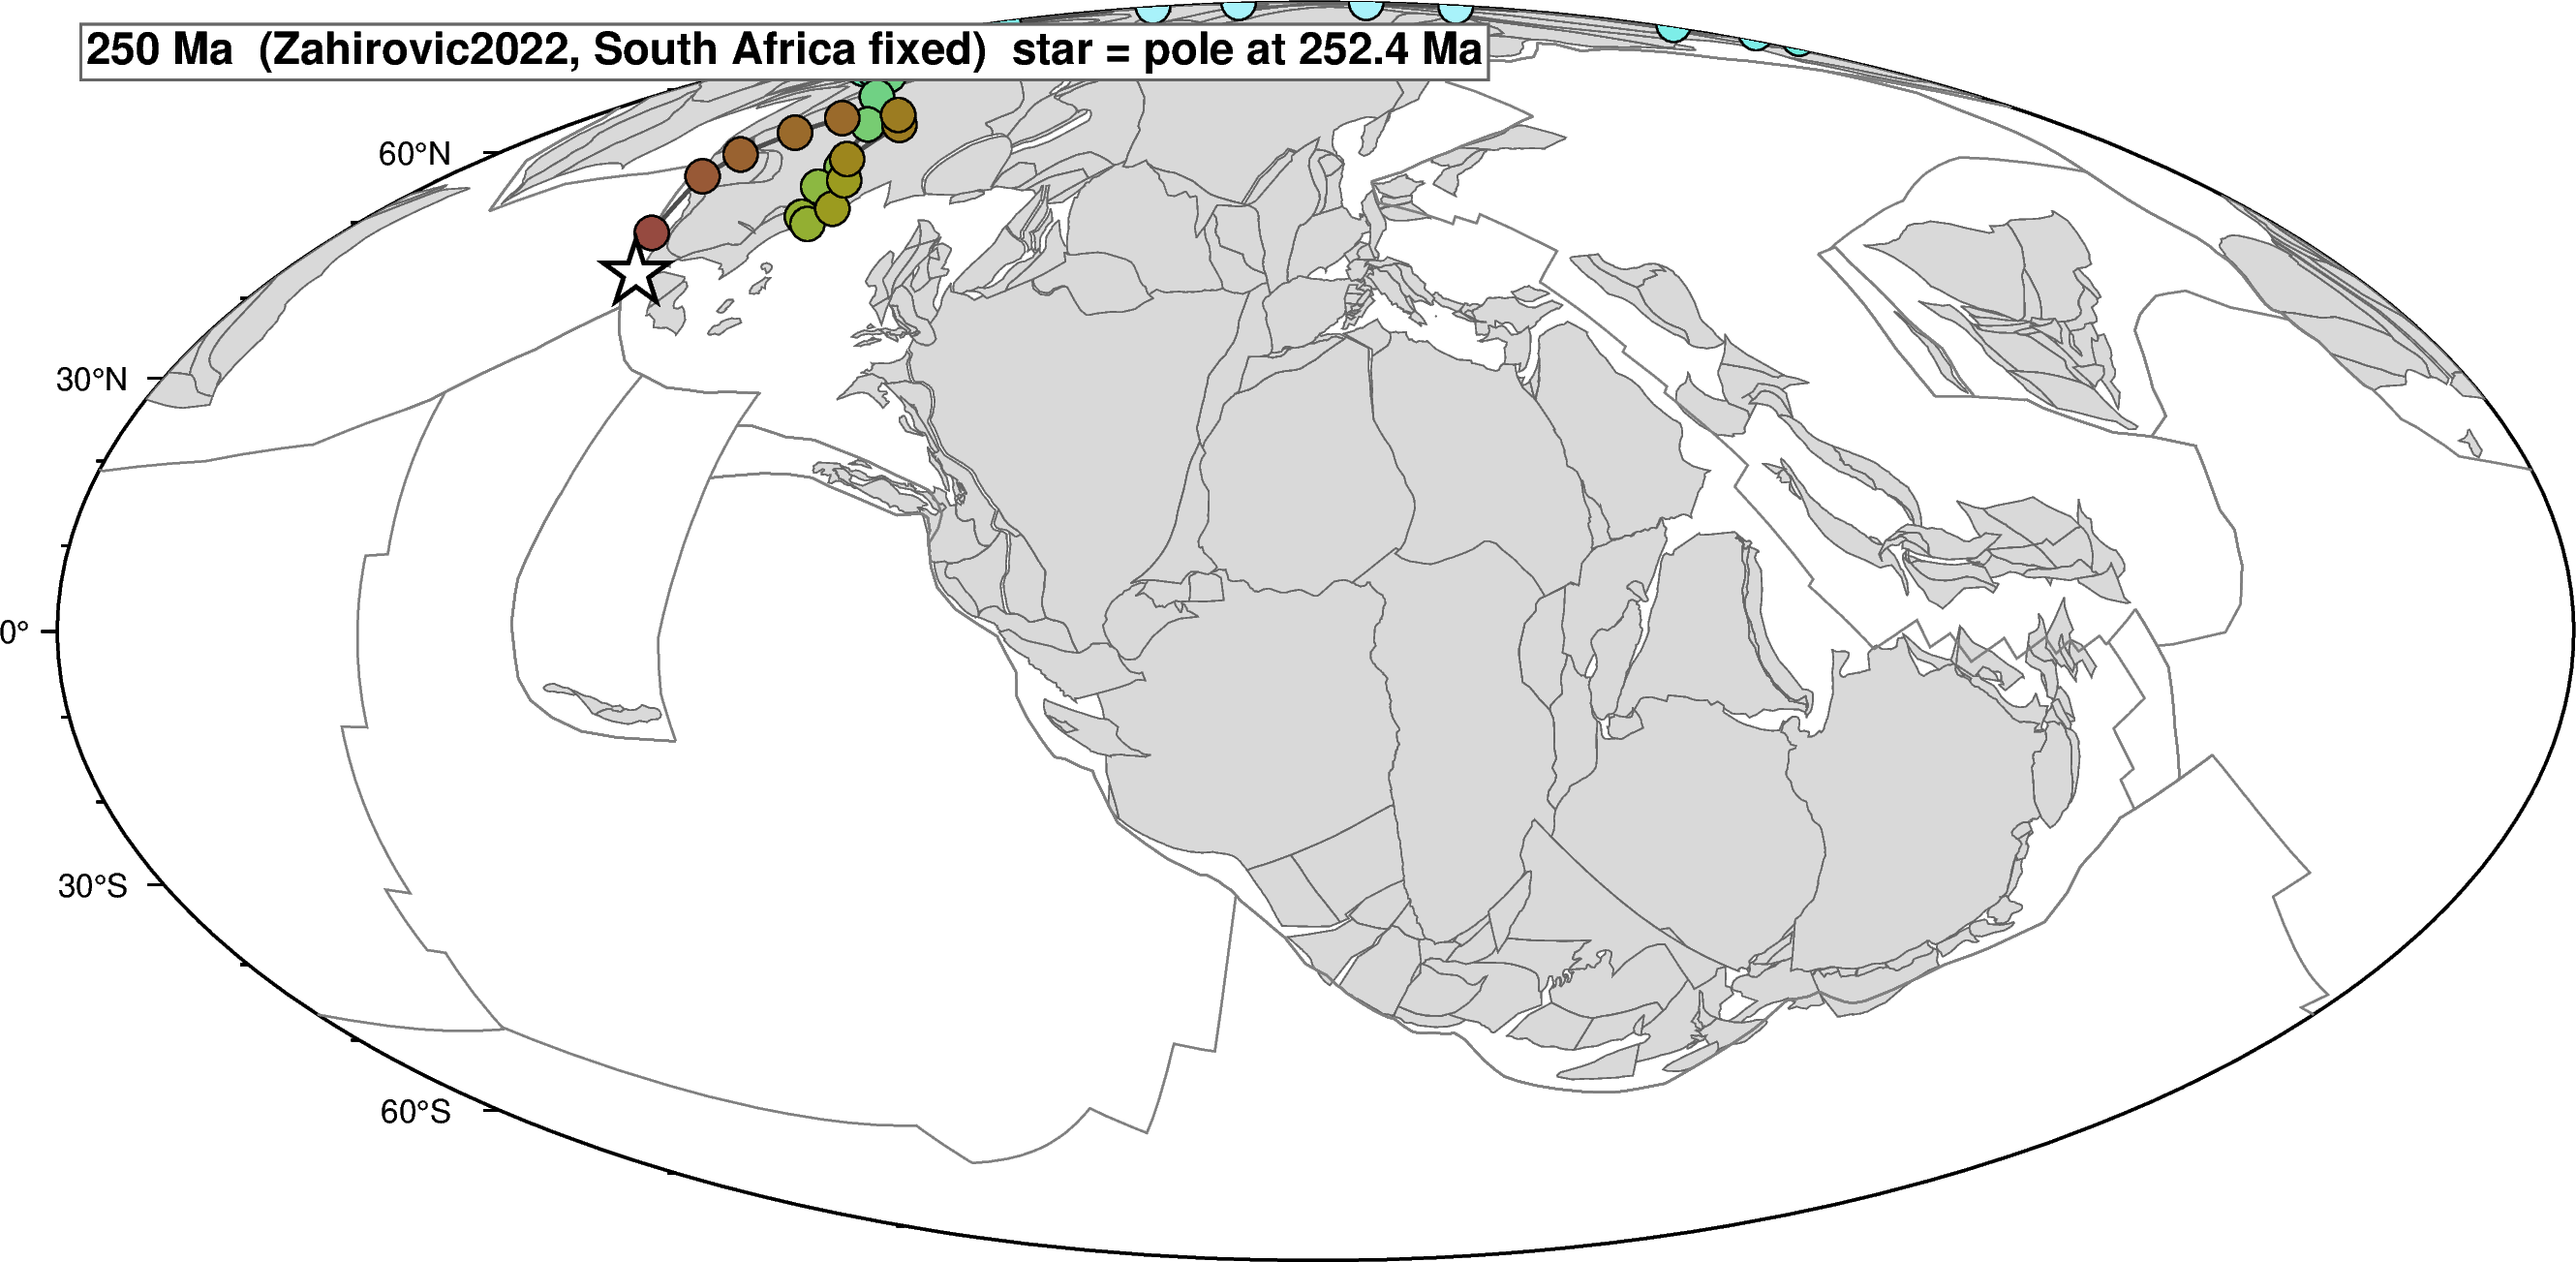


=== 320 Ma ===


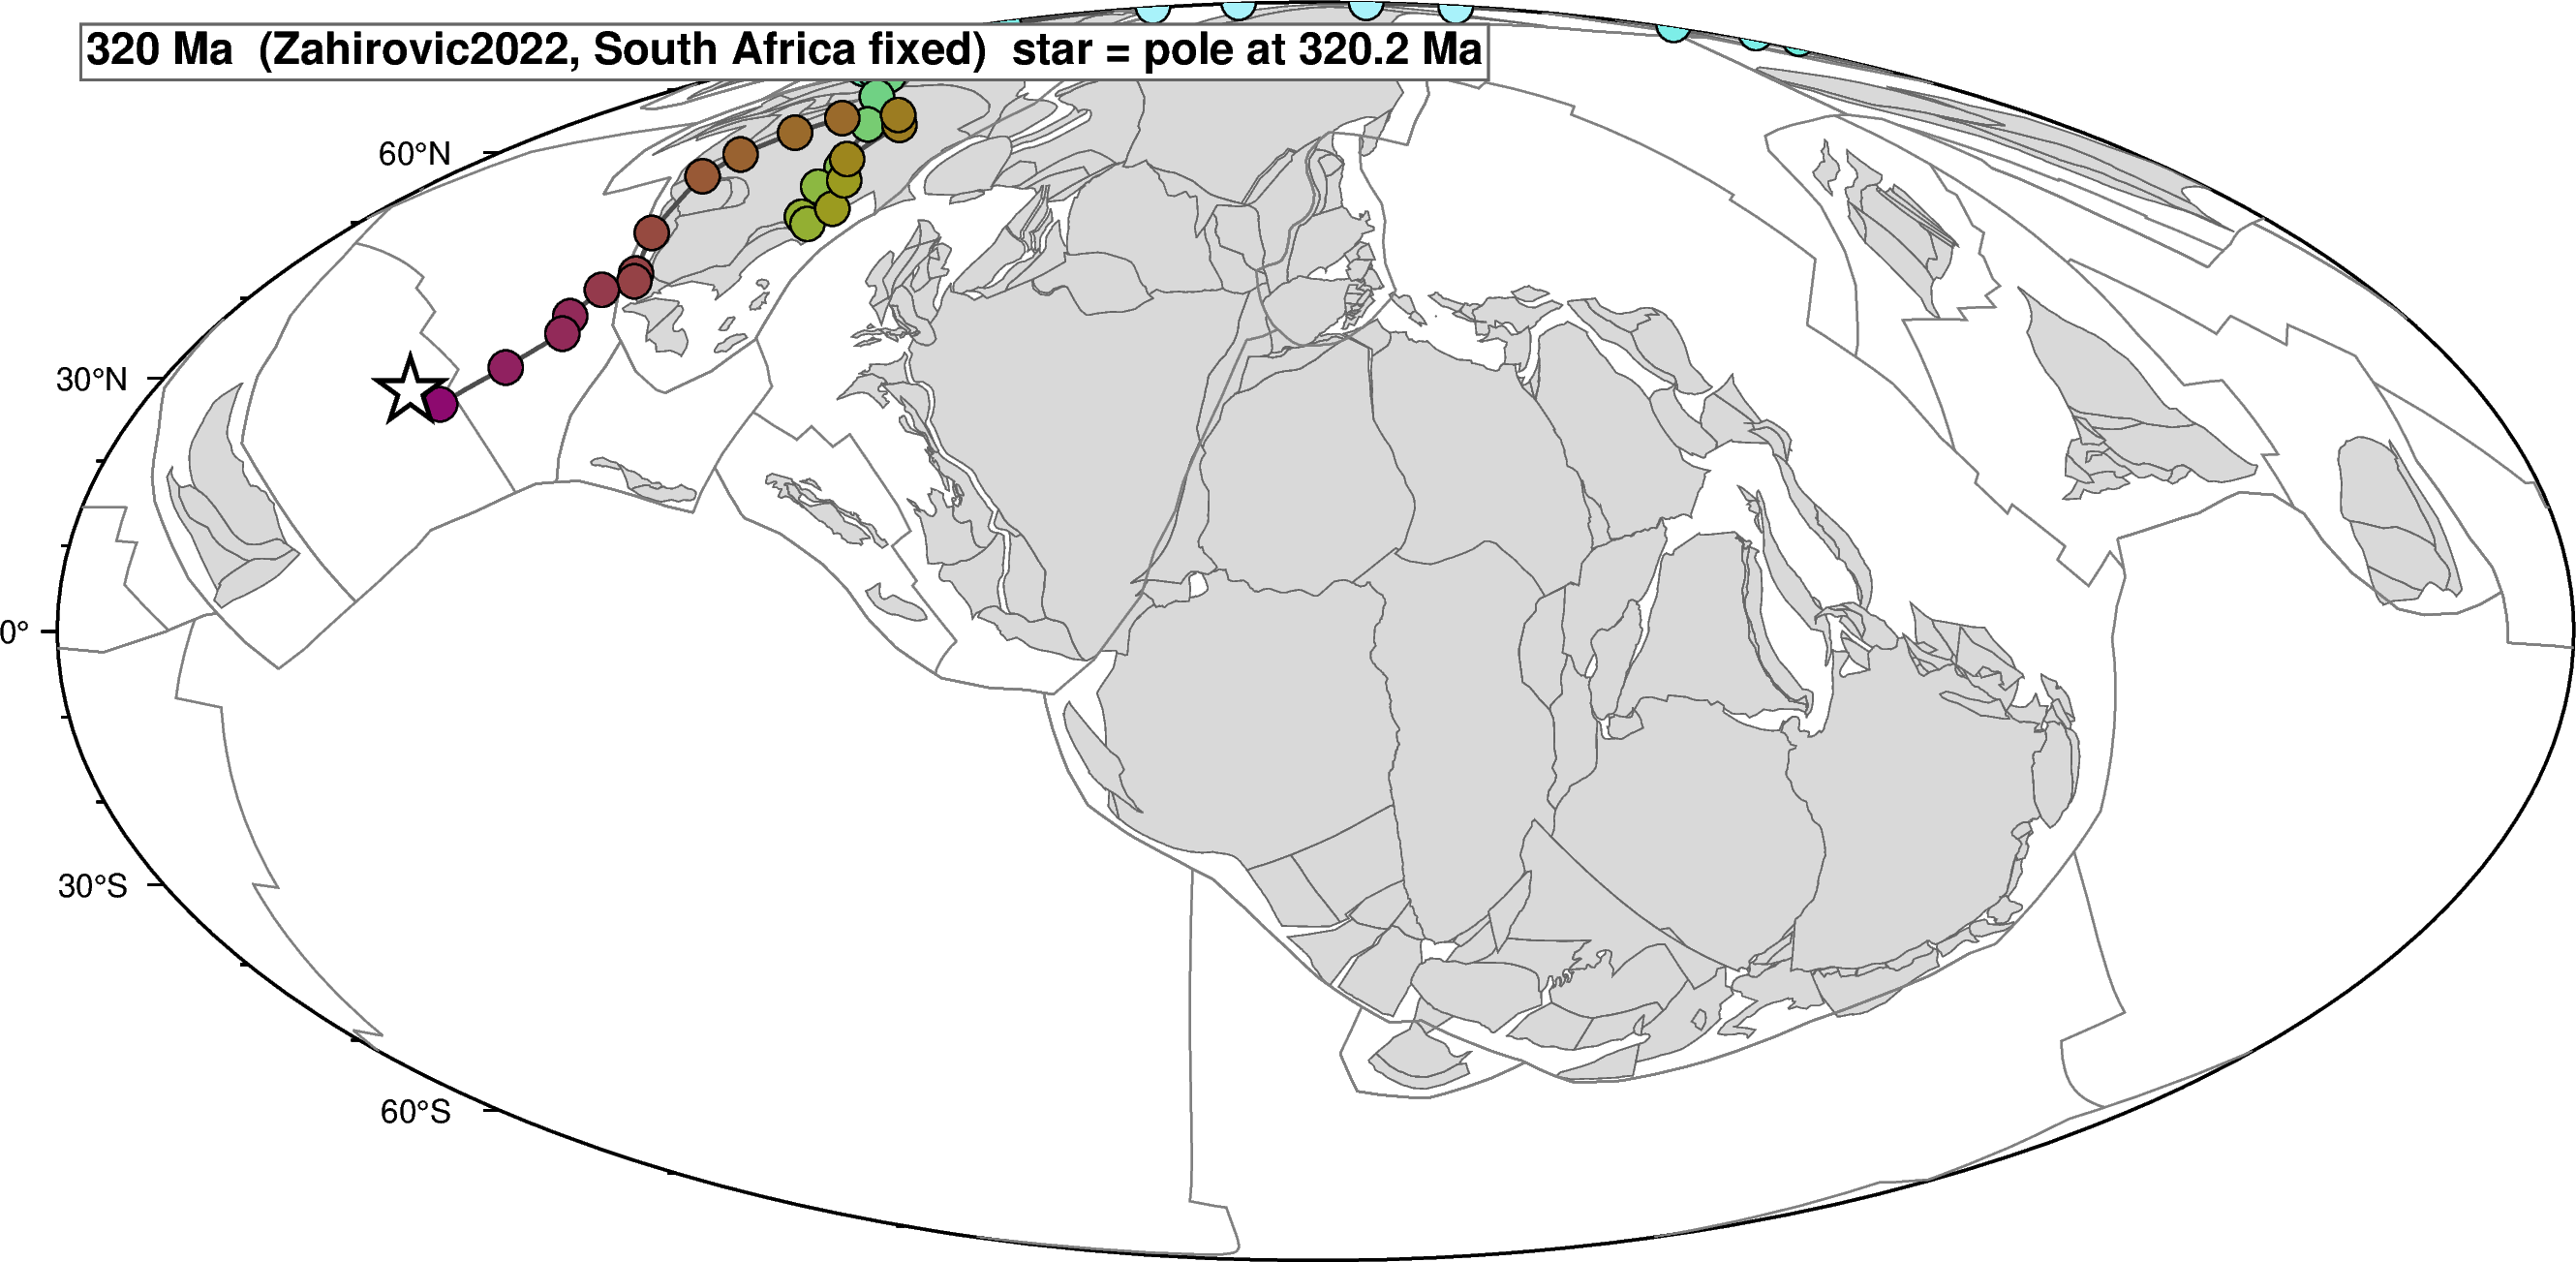

In [5]:
# Cell 4 — paleogeographic reconstruction renderer
def render_apwp_panel(t):
    gplot = gplately.PlotTopologies(
        plate_reconstruction=recon,
        coastlines=model.get_coastlines(),
        continents=model.get_continental_polygons(),
        COBs=model.get_COBs(),
        time=float(t),
    
    plot_engine=gplately.PygmtPlotEngine(),
    )
    visible = apwp[apwp["age"] <= t].copy()
    cur = apwp.loc[(apwp["age"] - float(t)).abs().idxmin()]       # nearest tabulated pole

    fig = pygmt.Figure()
    fig.basemap(region="d", projection="W0/22c", frame=["af"])
    gplot.plot_continents(fig, fill="gray85", pen="0.3p,gray40")
    gplot.plot_all_topological_sections(fig, pen="0.5p,gray50")

    if len(visible) > 0:
        pygmt.makecpt(cmap="hawaii", series=[0, MAX_AGE_MA, 10], reverse=True)
        fig.plot(x=visible["pole_lon"], y=visible["pole_lat"],
                 pen="1p,gray30")                              # APWP track
        fig.plot(x=visible["pole_lon"], y=visible["pole_lat"],
                 style="c0.30c", fill=visible["age"], cmap=True,
                 pen="0.5p,black")
    # pole nearest in age to the map age: position of the north rotation axis
    fig.plot(x=[cur["pole_lon"]], y=[cur["pole_lat"]], style="a0.6c",
             fill="white", pen="1p,black")

    fig.text(text=f"{t:.0f} Ma  ({MODEL_NAME}, South Africa fixed)  star = pole at {cur['age']:.1f} Ma",
             position="TL", offset="0.25c/-0.25c", justify="TL",
             font="11p,Helvetica-Bold,black",
             fill="white", pen="0.6p,gray40")
    return fig

# Render five static panels at AGES_TO_RENDER
for t in AGES_TO_RENDER:
    print(f"\n=== {t} Ma ===")
    fig = render_apwp_panel(t)
    fig.show(width=1100)
    display(HTML('<div style="height:1cm"></div>'))


## 4. Panel slider — scrub through time

The slider runs from 0 to `MAX_AGE_MA` (the last tabulated pole is 320.2 Ma).


Row
    [0] IntSlider(end=320, label='Reconstruction t..., name='Reconstruction t..., step=10)
    [1] ParamFunction(function, _pane=PNG, defer_load=False)
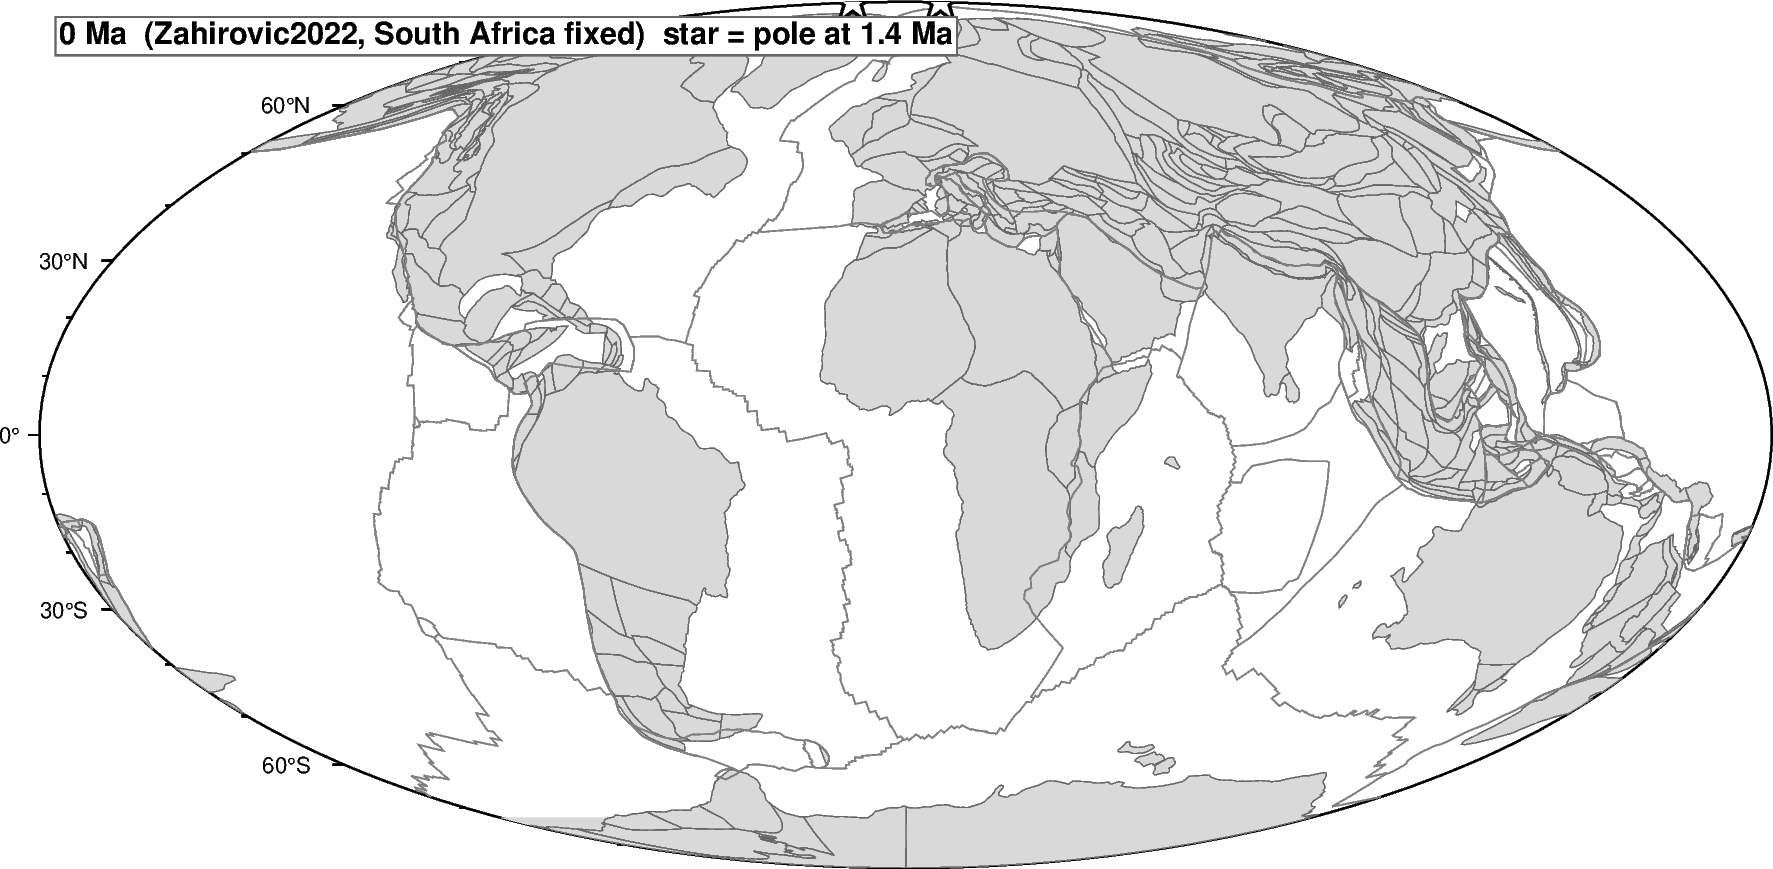

In [6]:
# Cell 5 — Panel slider
def panel_view(t):
    fig = render_apwp_panel(t)
    out = "panel_cache/apwp_{:03d}.png".format(int(t))
    import os; os.makedirs("panel_cache", exist_ok=True)
    fig.savefig(out, dpi=200)
    return pn.pane.PNG(out, width=900)

slider = pn.widgets.IntSlider(name="Reconstruction time (Ma)",
                              start=0, end=MAX_AGE_MA, step=10, value=0)
dashboard = pn.Row(slider, pn.bind(panel_view, t=slider))
dashboard


## Extend this

- **A different frame.** A pole is only meaningful together with its reference plate. For an APWP referenced to another craton (for example Laurentia or Baltica) change both the CSV and `ANCHOR_PLATE_ID` to that craton's plate id.
- **Compare APWPs.** Plot two published APWPs for the same frame as two coloured series. The differences between them bound the published uncertainty on the path itself.
- **Show A95.** The table has an `A95` column. Draw a small circle of radius `A95` around each pole (for example with `pygmt.Figure.plot(style="E-")` and the radius as major/minor axes).
- **Compare with T37.** T37 compares model-predicted paleolatitudes of a site with the same APWP.
- **Animate to MP4.** Loop the renderer over all ages in 5 Myr steps and stitch the frames with ffmpeg (recipe in T06).

## References

- Vaes, B., van Hinsbergen, D.J.J., van de Lagemaat, S.H.A., van der Wiel, E., Lom, N., Advokaat, E.L., Boschman, L.M., Gallo, L.C., Greve, A., Guilmette, C., Li, S., Lippert, P.C., Montheil, L., Qayyum, A. & Langereis, C.G. (2023). A global apparent polar wander path for the last 320 Ma calculated from site-level paleomagnetic data. *Earth-Sci. Rev.* 245, 104547. https://doi.org/10.1016/j.earscirev.2023.104547
- Mather, B.R. et al. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11, 3–10.
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371–383. https://doi.org/10.1002/gdj3.146
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Tong, J.-H., Ngo, L., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J. & Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515
